# DSMarket — Del pronóstico al estante: política de abastecimiento

**De:** Nicole, Data Science
**Para:** Paul (Director Financiero), Michelle (Chief Digital Officer)

Las tres tareas anteriores terminaron en un pronóstico. Un pronóstico, por sí solo, no repone nada: alguien tiene que decidir **cuántas unidades pedir, de qué producto, para qué tienda y con qué frecuencia**. Este documento propone cómo convertir las predicciones en esa decisión, y —más importante— **cuantifica cuánto vale hacerlo bien**.

La estructura es: primero la teoría que gobierna la decisión (secciones 2 y 3), después la propuesta concreta simulada sobre datos reales (4 a 7), y al final el diseño de cómo llevarlo a producción y escalarlo (8 y 9).

Una aclaración de alcance desde el principio: DSMarket no nos dio datos de costes, márgenes ni plazos de entrega. Todo lo que sigue usa **supuestos explícitos y parametrizados**, y la sección 5.1 muestra exactamente cuánto cambia la recomendación si esos supuestos cambian. Es la parte que hay que validar con Finanzas antes de aplicar nada.

## 1. Configuración

In [1]:
import os, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy.stats import norm
warnings.filterwarnings('ignore')

DATA_DIR = "data_dsmarket/data_dsmarket"
CACHE = "cache_forecast"
pd.set_option('display.max_columns', 60)
%matplotlib inline

DSMARKET_NAVY = "#0a2a5c"; DSMARKET_BLUE = "#2a78d6"
DSMARKET_GOLD = "#eda100"; DSMARKET_GREEN = "#6a9f1f"
DSMARKET_BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#0d366b"]
dsmarket_blues_cmap = LinearSegmentedColormap.from_list("dsmarket_blues", DSMARKET_BLUE_RAMP)
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e1e0d9",
    "figure.facecolor": "white", "axes.facecolor": "white"})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"

## 2. El marco teórico: qué decisión estamos tomando realmente

### 2.1. El problema del vendedor de diarios

La decisión de reposición es, en su forma más simple, el problema clásico del **newsvendor**: pedir una cantidad hoy sin saber la demanda de mañana, sabiendo que quedarse corto y quedarse largo cuestan cosas distintas.

- **Coste de faltante** ($C_u$, *underage*): el margen que se pierde cuando el cliente quiere el producto y no está. En retail hay además un coste de reputación difícil de medir.
- **Coste de sobrante** ($C_o$, *overage*): el capital inmovilizado, el espacio en el lineal, y —si el producto es perecedero— la merma.

El resultado central de la teoría es que la cantidad óptima no es la demanda esperada, sino un **percentil** de la distribución de demanda:

$$\text{Nivel de servicio óptimo} = \frac{C_u}{C_u + C_o}$$

Esto es lo que justifica todo el trabajo de la Tarea 3 sobre intervalos de predicción: **pedir según la predicción media es óptimo solo si faltante y sobrante cuestan exactamente lo mismo**, cosa que casi nunca ocurre. En la Tarea 3 medimos que la predicción media queda por encima de la demanda real solo en el 68 % de los días-producto. Conviene no leer ese número como "un tercio de la demanda se pierde": es un porcentaje de **días**, no de **unidades**. Cuánta demanda se pierde de verdad depende del inventario que se arrastra de un día a otro, y eso lo mide la simulación de la sección 4.

### 2.2. Stock de seguridad: por qué la fórmula del manual no sirve tal cual

La fórmula clásica del stock de seguridad es $SS = z_{\alpha} \cdot \sigma_{L} $, donde $\sigma_L$ es la desviación típica de la demanda durante el plazo de cobertura y $z_\alpha$ el valor de la normal para el nivel de servicio buscado. Tiene dos supuestos que en este catálogo se rompen:

1. **Supone demanda normal.** La demanda de estos productos es asimétrica y discreta: más de la mitad de los días-producto no registra ninguna venta (57 %, notebook 03, sección 8), y en el grupo de venta esporádica de la Tarea 2 el 39 % de los días no se vende nada. Una normal ajustada a eso da stocks negativos en la cola izquierda y subestima la derecha.
2. **Supone que $\sigma$ es estable y se estima del pasado.** Pero la dispersión cambia con el día de la semana, la temporada y el precio — justamente lo que el modelo de la Tarea 3 aprende.

Nuestra propuesta usa el **modelo cuantílico** entrenado en la Tarea 3 para estimar la dispersión: en vez de calcular $\sigma$ del histórico, la derivamos de la distancia entre el percentil 90 predicho y la media predicha, $\sigma_t = (p90_t - \mu_t)/z_{0.90}$. Así la dispersión es **condicional**: cambia día a día según lo que el modelo sabe de ese producto en ese momento.

La sección 6 pone a prueba si esto realmente sirve, y el resultado no es el que esperábamos.

### 2.3. La política: revisión periódica (R, S)

Elegimos una política de **revisión periódica con nivel de reposición**, la estándar en retail con entregas programadas:

- Cada **R = 7 días** se revisa el inventario de cada producto en cada tienda.
- Se pide lo necesario para llevar la posición de stock (inventario en tienda + pedidos en camino) hasta un **nivel objetivo S**.
- El pedido tarda **L = 2 días** en llegar.

El nivel objetivo tiene que cubrir la demanda de todo el período en que la decisión queda comprometida, que es el ciclo de revisión más el plazo de entrega — **R + L = 9 días**:

$$S = \underbrace{\sum_{i=1}^{R+L} \mu_i}_{\text{demanda esperada}} + \underbrace{z_{\alpha}\sqrt{\sum_{i=1}^{R+L}\sigma_i^2}}_{\text{stock de seguridad}}$$

*(La suma de varianzas asume independencia entre días. Es una simplificación: si la demanda está autocorrelacionada, subestima la dispersión real. Lo retomamos en la sección 6, porque resultó importar más de lo previsto.)*

## 3. Segmentar antes de decidir: ABC × XYZ

Aplicar la misma política a 30.490 combinaciones producto-tienda sería un error: no todas merecen la misma atención ni el mismo nivel de servicio. La segmentación estándar en gestión de inventarios cruza dos ejes:

- **ABC — por valor.** A: el 80% de la facturación. B: el 15% siguiente. C: el 5% restante.
- **XYZ — por predictibilidad**, medida con el coeficiente de variación de la demanda diaria. X: estable. Y: variable. Z: errática.

La gracia del cruce es que las dos preguntas son independientes: un producto puede facturar mucho y ser impredecible (AZ), o facturar poco y ser regular (CX). Y cada celda pide una política distinta.

In [2]:
V = np.load(f"{CACHE}/V_ventas.npy") if os.path.exists(f"{CACHE}/V_ventas.npy") else None
if V is None:      # primera ejecución: reconstruimos la matriz de ventas desde el CSV original
    sales = pd.read_csv(f"{DATA_DIR}/item_sales.csv")
    day_cols = [c for c in sales.columns if c.startswith('d_')]
    V = sales[day_cols].to_numpy(dtype=np.int16)
    np.save(f"{CACHE}/V_ventas.npy", V)
    sales_meta = sales[['id','item','category','department','store','store_code','region']]
    sales_meta.to_csv(f"{CACHE}/meta.csv", index=False)
    del sales
meta = pd.read_csv(f"{CACHE}/meta.csv")
calendar = pd.read_csv(f"{DATA_DIR}/daily_calendar_with_events.csv")
calendar['date'] = pd.to_datetime(calendar['date'])
segmentacion = pd.read_csv(f"{CACHE}/segmentacion_productos.csv", index_col=0)   # Tarea 2 (notebook 02)
meta['grupo'] = meta['item'].map(segmentacion['nombre_grupo'])

n_series, n_days = V.shape
s, e = n_days - 28, n_days                       # ventana de simulación = fold 3 de la Tarea 3
H = e - s
demanda = V[:, s:e].astype(np.float64)
# predicciones del modelo final de la Tarea 3 (sección 12) para esta ventana: media y percentil 90
media_pred = np.load(f"{CACHE}/final_eval_media.npy").astype(np.float64)
p90_pred = np.load(f"{CACHE}/final_eval_p90.npy").astype(np.float64)
print(f"ventana simulada: {calendar['date'].iloc[s].date()} a {calendar['date'].iloc[e-1].date()} ({H} días)")
print(f"series: {n_series:,} | demanda real del período: {demanda.sum():,.0f} unidades")

ventana simulada: 2016-03-28 a 2016-04-24 (28 días)
series: 30,490 | demanda real del período: 1,183,626 unidades


In [3]:
# precio medio de cada serie en la ventana (para valorizar), reconstruido igual que en la Tarea 3
prices = pd.read_csv(f"{DATA_DIR}/item_prices.csv").dropna(subset=['yearweek'])
prices['yearweek'] = prices['yearweek'].astype(int)
fila_de = pd.Series(np.arange(len(meta)), index=(meta['item'] + '|' + meta['store_code']).values)
prices['row'] = (prices['item'] + '|' + prices['store_code']).map(fila_de).astype(np.int32)
semanas = np.sort(prices['yearweek'].unique())
n_weeks = int(np.ceil(n_days / 7))
prices['widx'] = prices['yearweek'].map({w: i for i, w in enumerate(semanas)}) - (len(semanas) - n_weeks)
pw = prices[prices['widx'] >= 0]
P_week = np.full((n_series, n_weeks), np.nan, dtype=np.float32)
P_week[pw['row'].values, pw['widx'].values] = pw['sell_price'].values.astype(np.float32)
P = np.repeat(P_week, 7, axis=1)[:, :n_days]
del P_week, prices, pw

precio = np.nanmean(P[:, s:e], axis=1)
precio = np.where(np.isnan(precio), np.nanmedian(precio), precio)
activo = ~np.isnan(P[:, s:e]).all(axis=1)
print(f"series activas en la ventana: {activo.sum():,} de {n_series:,}")

series activas en la ventana: 30,490 de 30,490


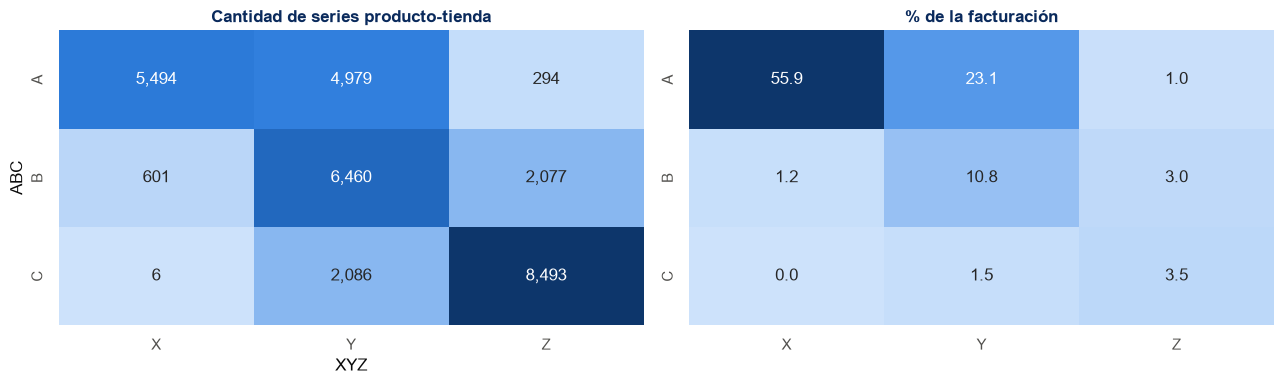

In [4]:
hist90 = V[:, s-90:s].astype(np.float64)
facturacion = hist90.sum(axis=1) * precio
orden = np.argsort(-facturacion)
acumulado = np.cumsum(facturacion[orden]) / facturacion.sum()
clase_abc = np.empty(n_series, dtype='<U1')
clase_abc[orden] = np.where(acumulado <= 0.80, 'A', np.where(acumulado <= 0.95, 'B', 'C'))

mu90, sd90 = hist90.mean(axis=1), hist90.std(axis=1)
cv = np.where(mu90 > 0, sd90 / np.maximum(mu90, 1e-9), 99.0)
clase_xyz = np.where(cv <= 1.0, 'X', np.where(cv <= 2.0, 'Y', 'Z'))
celda = np.char.add(clase_abc, clase_xyz)

tabla = pd.crosstab(pd.Series(clase_abc[activo], name='ABC'), pd.Series(clase_xyz[activo], name='XYZ'))
fac = (pd.Series(facturacion[activo]).groupby([pd.Series(clase_abc[activo]), pd.Series(clase_xyz[activo])])
       .sum().unstack() / facturacion[activo].sum() * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(tabla, annot=True, fmt=',d', cmap=dsmarket_blues_cmap, cbar=False, ax=axes[0])
axes[0].set_title('Cantidad de series producto-tienda', color=DSMARKET_NAVY, fontweight='bold')
sns.heatmap(fac, annot=True, fmt='.1f', cmap=dsmarket_blues_cmap, cbar=False, ax=axes[1])
axes[1].set_title('% de la facturación', color=DSMARKET_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

In [5]:
cruce = pd.crosstab(pd.Series(meta['grupo'].values[activo], name='grupo de producto (Tarea 2)'),
                    pd.Series(clase_xyz[activo], name='XYZ'), normalize='index') * 100
cruce['series'] = pd.Series(meta['grupo'].values[activo]).value_counts()
cruce['% de la facturación'] = (pd.Series(facturacion[activo]).groupby(meta['grupo'].values[activo]).sum()
                                / facturacion[activo].sum() * 100)
cruce.sort_values('X', ascending=False).round(1)

XYZ,X,Y,Z,series,% de la facturación
grupo de producto (Tarea 2),,,,,
Alta rotación diaria,52.8,38.9,8.3,6790,38.4
Pico de fin de semana,17.2,56.2,26.6,8820,25.1
"Precio alto, pocas unidades",8.9,41.3,49.8,2180,13.4
Rotación baja sin picos,8.6,50.1,41.4,7450,15.6
Pico de diciembre,7.3,36.5,56.2,1200,2.9
Venta esporádica con pico en eventos,2.0,21.1,76.9,4050,4.7


**Hallazgo: el catálogo está muy desequilibrado, y eso es una oportunidad.**

- **AX: 5.494 series (18 % del catálogo) que suman el 55,9 % de la facturación y además son predecibles.** Es donde automatizar la reposición rinde más: mucho dinero en juego y demanda estable. Solo con estas series ya se cubre más de la mitad del valor.
- **CZ: 8.493 series (28 % del catálogo) que suman el 3,5 % de la facturación y son erráticas.** Casi un tercio del catálogo aporta menos del 4 % del negocio. Aquí no compensa invertir en precisión, y conviene revisar si algunos de esos productos deben seguir en el surtido.
- **CX está prácticamente vacío (6 series).** Es lógico: un producto que se vende de forma estable difícilmente factura poco.

El cruce con los grupos de producto de la Tarea 2 muestra que **los dos ejes miden cosas distintas y se complementan**:

- **Alta rotación diaria** es el único grupo con mayoría de series estables (X: 53 %) y suma el 38 % de la facturación.
- **Venta esporádica con pico en eventos** es casi todo errático (Z: 77 %), seguido de **Pico de diciembre** (56 %) y **Precio alto, pocas unidades** (50 %).
- **Pico de fin de semana** y **Rotación baja sin picos** son sobre todo Y, con una parte importante de Z (27 % y 41 %).

El grupo dice *cómo* se vende un producto (a diario, en fin de semana, en diciembre, en eventos) y la clase XYZ dice *cuánto se puede fiar* la previsión de cada serie. Para reponer hacen falta los dos.

## 4. La simulación: tres políticas sobre datos reales

Comparamos tres formas de fijar el nivel objetivo S, simulando día a día las cuatro semanas del período de validación con la **demanda real** que efectivamente ocurrió:

1. **Actual** — pedir la predicción media, sin stock de seguridad. Es la política implícita de "hacerle caso al pronóstico".
2. **Stock de seguridad clásico** — la fórmula del manual, con σ estimado del histórico reciente.
3. **Modelo cuantílico** — σ derivado del percentil 90 que predice el modelo.

Las dos últimas apuntan al **mismo nivel de servicio objetivo (90%)**, para que la comparación sea justa: lo único que cambia es cómo se estima la incertidumbre. Qué nivel conviene es otra pregunta, y la responde la sección 5.

La simulación respeta la mecánica real: el inventario se consume día a día, los pedidos se hacen solo los días de revisión, tardan dos días en llegar, y **lo que no hay en el estante se pierde** (no hay pedidos pendientes que el cliente espere).

In [6]:
R, L = 7, 2                       # revisión semanal, plazo de entrega 2 días
VENTANA = R + L
MARGEN = 0.25                     # margen bruto sobre el precio de venta  ← SUPUESTO
TASA_MANTENIMIENTO = 0.25         # coste anual de mantener stock, sobre el coste unitario  ← SUPUESTO
Z = {0.50: 0.0, 0.80: 0.8416, 0.85: 1.0364, 0.90: 1.2816, 0.95: 1.6449, 0.98: 2.0537}
costo_unitario = precio * (1 - MARGEN)

sigma_modelo = np.maximum(p90_pred - media_pred, 0) / Z[0.90]
sigma_hist = np.repeat(V[:, s-28:s].astype(np.float64).std(axis=1, keepdims=True), H, axis=1)
extender = lambda M: np.hstack([M, np.repeat(M[:, -7:].mean(axis=1, keepdims=True), VENTANA, axis=1)])
mu_ext, sig_mod_ext, sig_his_ext = extender(media_pred), extender(sigma_modelo), extender(sigma_hist)

def nivel_objetivo(t, sigma_ext, z):
    mu = mu_ext[:, t:t+VENTANA].sum(axis=1)
    sd = np.sqrt((sigma_ext[:, t:t+VENTANA] ** 2).sum(axis=1))
    return mu + z * sd

def simular(fn_nivel):
    """Política (R,S): consumo diario, revisión cada R días, entrega en L días."""
    inv = fn_nivel(0).copy()
    pipeline = np.zeros((n_series, L + 1))
    servido = np.zeros(n_series); perdido = np.zeros(n_series); inv_acum = np.zeros(n_series)
    for t in range(H):
        inv += pipeline[:, 0]
        pipeline = np.hstack([pipeline[:, 1:], np.zeros((n_series, 1))])
        atendido = np.minimum(inv, demanda[:, t])
        servido += atendido; perdido += demanda[:, t] - atendido; inv -= atendido
        if t % R == 0 and t > 0:
            pedido = np.maximum(fn_nivel(t) - (inv + pipeline.sum(axis=1)), 0)
            pipeline[:, L - 1] += pedido
        inv_acum += inv
    return {'servido': servido, 'perdido': perdido, 'inv_medio': inv_acum / H, 'remanente': inv}

def economia(r, etiqueta):
    a = activo
    margen_perdido = (r['perdido'][a] * precio[a] * MARGEN).sum()
    mantenimiento = (r['inv_medio'][a] * costo_unitario[a]).sum() * TASA_MANTENIMIENTO / 365 * H
    return {'política': etiqueta,
            'nivel de servicio %': r['servido'][a].sum() / demanda[a].sum() * 100,
            'unidades perdidas': r['perdido'][a].sum(),
            'inventario medio (uds)': r['inv_medio'][a].sum(),
            'margen perdido USD': margen_perdido, 'mantenimiento USD': mantenimiento,
            'coste total USD': margen_perdido + mantenimiento,
            'remanente final (uds)': r['remanente'][a].sum()}

POLITICAS = {
    'Actual (a la predicción media)':        lambda t: nivel_objetivo(t, sig_mod_ext, 0.0),
    'Stock de seguridad clásico (σ histórico)': lambda t: nivel_objetivo(t, sig_his_ext, Z[0.90]),
    'Modelo cuantílico (σ del modelo)':      lambda t: nivel_objetivo(t, sig_mod_ext, Z[0.90]),
}
resultados = {nombre: simular(fn) for nombre, fn in POLITICAS.items()}
comparacion = pd.DataFrame([economia(r, n) for n, r in resultados.items()]).set_index('política')
base = comparacion.loc['Actual (a la predicción media)', 'coste total USD']
comparacion['ahorro vs actual %'] = (base - comparacion['coste total USD']) / base * 100
comparacion.round(1)

,nivel de servicio %,unidades perdidas,inventario medio (uds),margen perdido USD,mantenimiento USD,coste total USD,remanente final (uds),ahorro vs actual %
política,,,,,,,,
Actual (a la predicción media),86.6,159038.5,197604.3,164543.4,11156.0,175699.4,140932.2,0.0
Stock de seguridad clásico (σ histórico),95.3,56048.3,326899.7,57222.3,18961.8,76184.1,267993.6,56.6
Modelo cuantílico (σ del modelo),95.9,48945.1,339586.3,47651.5,19943.8,67595.3,279790.2,61.5


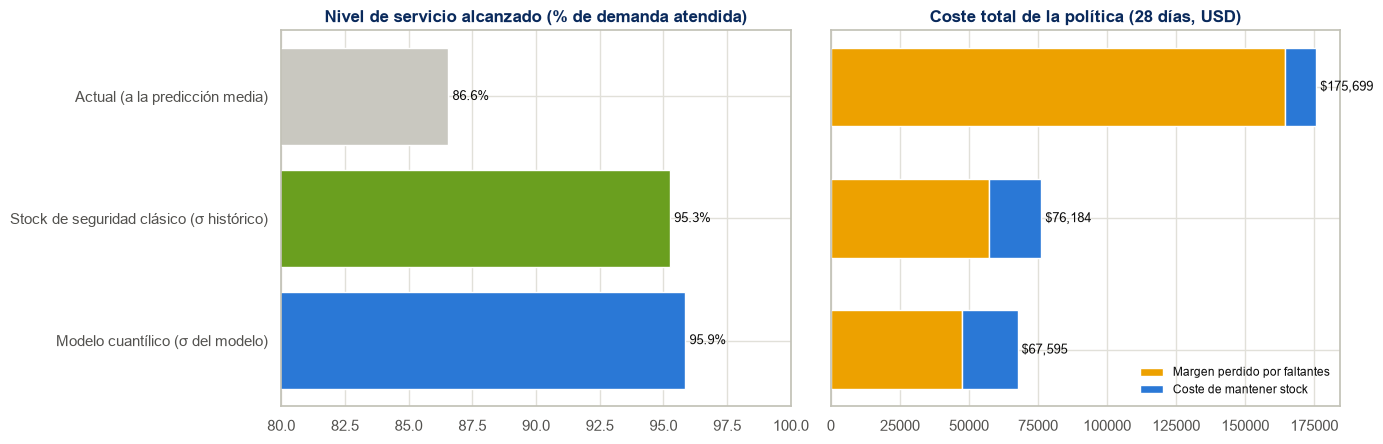

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
nombres = list(comparacion.index)
colores = ['#c9c8c0', DSMARKET_GREEN, DSMARKET_BLUE]

axes[0].barh(nombres[::-1], comparacion['nivel de servicio %'][::-1], color=colores[::-1])
axes[0].set_xlim(80, 100)
axes[0].set_title('Nivel de servicio alcanzado (% de demanda atendida)', color=DSMARKET_NAVY, fontweight='bold')
for i, v in enumerate(comparacion['nivel de servicio %'][::-1]):
    axes[0].text(v, i, f' {v:.1f}%', va='center', fontsize=9)

anchura = 0.6
axes[1].barh(nombres[::-1], comparacion['margen perdido USD'][::-1], anchura,
             color=DSMARKET_GOLD, label='Margen perdido por faltantes')
axes[1].barh(nombres[::-1], comparacion['mantenimiento USD'][::-1], anchura,
             left=comparacion['margen perdido USD'][::-1], color=DSMARKET_BLUE, label='Coste de mantener stock')
axes[1].set_title('Coste total de la política (28 días, USD)', color=DSMARKET_NAVY, fontweight='bold')
axes[1].legend(frameon=False, fontsize=8.5)
axes[1].set_yticklabels([])
for i, v in enumerate(comparacion['coste total USD'][::-1]):
    axes[1].text(v, i, f' ${v:,.0f}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

**Hallazgo: la política actual pierde dinero por quedarse sin stock, no por tener demasiado.**

| Política | Servicio | Coste total (28 días) | Ahorro |
|---|---|---|---|
| Actual (pedir la predicción media) | 86,6 % | 175.699 $ | — |
| Stock de seguridad clásico | 95,3 % | 76.184 $ | 56,6 % |
| **Modelo cuantílico** | **95,9 %** | **67.595 $** | **61,5 %** |

*(las dos políticas con stock de seguridad, con un objetivo del 90 %)*

Tres lecturas:

1. **Pedir la predicción media cubre solo el 86,6 % de la demanda y cuesta 175.699 $ en cuatro semanas.** De eso, **164.543 $ son margen perdido** por roturas de stock y solo 11.156 $ el coste de mantener inventario. La política actual no es cara por tener stock parado: es cara porque **deja de vender**. Son 159.039 unidades que el cliente quiso comprar y no encontró.
2. **Cualquier política con stock de seguridad ahorra más del 55 %.** Es el mensaje más simple y más rentable del proyecto, y no necesita machine learning: solo aceptar que hay que tener algo más de lo que dice la previsión.
3. **El stock de seguridad calculado con el modelo cuantílico mejora al clásico un 11,3 %** (67.595 $ frente a 76.184 $), con un servicio algo mayor. Ahí es donde aporta el modelo de la Tarea 3: no tanto en predecir mejor la media como en **estimar mejor la incertidumbre**.

*Nota:* las predicciones son las del modelo final de la Tarea 3 (notebook 03, sección 12: 400 días de historia y eventos semanales) sobre la última ventana de validación, del 28 de marzo al 24 de abril de 2016.

## 5. La curva servicio-coste: cuánto cuesta cada punto de servicio

La comparación anterior fija el nivel de servicio en 90% y compara formas de llegar ahí. La otra pregunta —la que en realidad decide el negocio— es **a qué nivel de servicio conviene apuntar**. Recorremos la curva completa.

In [8]:
NIVELES = [0.50, 0.70, 0.80, 0.85, 0.90, 0.95, 0.98, 0.99]
sims_nivel = {sl: simular(lambda t, z=norm.ppf(sl) if sl > 0.5 else 0.0: nivel_objetivo(t, sig_mod_ext, z))
              for sl in NIVELES}

def costes(sl, margen=MARGEN, tasa=TASA_MANTENIMIENTO, merma=0.0):
    r = sims_nivel[sl]; a = activo
    cu = precio * (1 - margen)
    perdido = (r['perdido'][a] * precio[a] * margen).sum()
    mantener = (r['inv_medio'][a] * cu[a]).sum() * tasa / 365 * H
    descarte = (r['remanente'][a] * cu[a]).sum() * merma
    return {'objetivo': sl, 'servicio real %': r['servido'][a].sum()/demanda[a].sum()*100,
            'margen perdido': perdido, 'mantenimiento': mantener, 'merma': descarte,
            'coste total': perdido + mantener + descarte,
            'inventario medio': r['inv_medio'][a].sum(), 'remanente': r['remanente'][a].sum()}

curva = pd.DataFrame([costes(sl) for sl in NIVELES]).set_index('objetivo')
print(f"Nivel de servicio con menor coste total (sin merma): {curva['coste total'].idxmin():.0%}")
print()
Cu = np.median(precio) * MARGEN
Co = np.median(precio) * (1 - MARGEN) * TASA_MANTENIMIENTO / 365 * VENTANA
print("Newsvendor teórico, con estos supuestos:")
print(f"  Cu (margen perdido por unidad faltante):        {Cu:.3f} USD")
print(f"  Co (mantener una unidad sobrante {VENTANA} días):      {Co:.4f} USD")
print(f"  nivel de servicio óptimo = Cu/(Cu+Co) =        {Cu/(Cu+Co):.1%}")
curva.round(1)

Nivel de servicio con menor coste total (sin merma): 99%

Newsvendor teórico, con estos supuestos:
  Cu (margen perdido por unidad faltante):        1.062 USD
  Co (mantener una unidad sobrante 9 días):      0.0196 USD
  nivel de servicio óptimo = Cu/(Cu+Co) =        98.2%


,servicio real %,margen perdido,mantenimiento,merma,coste total,inventario medio,remanente
objetivo,,,,,,,
0.50,86.6,164543.4,11156.0,0.0,175699.4,197604.3,140932.2
0.70,91.7,98285.0,14596.5,0.0,112881.4,253327.5,194699.9
0.80,93.9,72017.9,16794.3,0.0,88812.2,288782.7,229486.3
0.85,94.9,59796.7,18176.3,0.0,77973.0,311073.1,251501.2
0.90,95.9,47653.6,19943.4,0.0,67597.0,339580.6,279784.5
0.95,97.0,34652.8,22606.2,0.0,57258.9,382526.2,322658.1
0.98,97.8,25040.6,25648.0,0.0,50688.6,431611.3,371789.8
0.99,98.2,20652.1,27694.6,0.0,48346.6,464654.0,404869.0


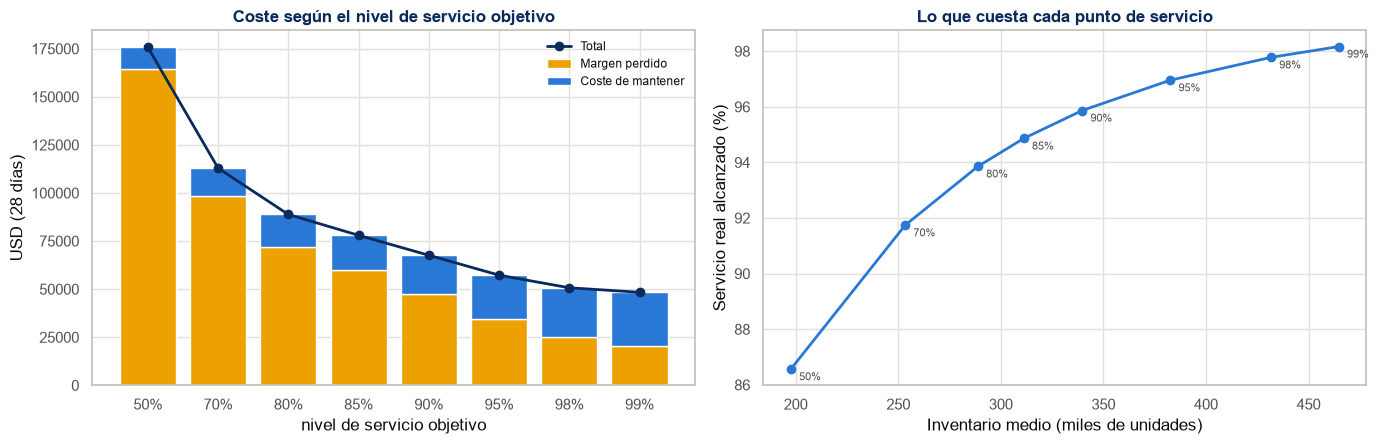

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
x = [f"{s:.0%}" for s in curva.index]
axes[0].bar(x, curva['margen perdido'], color=DSMARKET_GOLD, label='Margen perdido')
axes[0].bar(x, curva['mantenimiento'], bottom=curva['margen perdido'], color=DSMARKET_BLUE,
            label='Coste de mantener')
axes[0].plot(x, curva['coste total'], color=DSMARKET_NAVY, marker='o', linewidth=2, label='Total')
axes[0].set_title('Coste según el nivel de servicio objetivo', color=DSMARKET_NAVY, fontweight='bold')
axes[0].set_xlabel('nivel de servicio objetivo'); axes[0].set_ylabel('USD (28 días)')
axes[0].legend(frameon=False, fontsize=8.5)

ax2 = axes[1]
ax2.plot(curva['inventario medio']/1000, curva['servicio real %'], color=DSMARKET_BLUE,
         marker='o', linewidth=2)
for sl, row in curva.iterrows():
    ax2.annotate(f"{sl:.0%}", (row['inventario medio']/1000, row['servicio real %']),
                 textcoords='offset points', xytext=(6, -8), fontsize=8, color='#52514e')
ax2.set_xlabel('Inventario medio (miles de unidades)'); ax2.set_ylabel('Servicio real alcanzado (%)')
ax2.set_title('Lo que cuesta cada punto de servicio', color=DSMARKET_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

### 5.1. Sensibilidad: qué supuesto manda de verdad

El resultado anterior depende de dos números que **no tenemos** y que hay que pedirle a Finanzas: el margen bruto y el coste de que sobre stock. Recorremos los dos para ver cuál mueve la recomendación.

El coste de sobrante tiene dos componentes: el financiero (mantener capital inmovilizado, que es el que ya está en el cálculo) y la **merma** — la fracción del sobrante que directamente se pierde por caducidad, deterioro o falta de espacio. Para productos frescos la merma es el componente dominante, y no la conocemos.

In [10]:
filas = []
for merma in [0.0, 0.02, 0.05, 0.10, 0.20]:
    t = pd.DataFrame([costes(sl, merma=merma) for sl in NIVELES]).set_index('objetivo')
    filas.append({'merma sobre el remanente': f"{merma:.0%}", 'nivel óptimo': f"{t['coste total'].idxmin():.0%}",
                  'coste en el óptimo': t['coste total'].min(), 'coste al 90%': t.loc[0.90, 'coste total'],
                  'coste a la media (50%)': t.loc[0.50, 'coste total']})
sens_merma = pd.DataFrame(filas)

filas = []
for m in [0.10, 0.15, 0.25, 0.35]:
    t = pd.DataFrame([costes(sl, margen=m) for sl in NIVELES]).set_index('objetivo')
    filas.append({'margen bruto': f"{m:.0%}", 'nivel óptimo': f"{t['coste total'].idxmin():.0%}",
                  'coste en el óptimo': t['coste total'].min()})
sens_margen = pd.DataFrame(filas)
print("Sensibilidad a la merma:"); print(sens_merma.round(0).to_string(index=False))
print("\nSensibilidad al margen bruto (sin merma):"); print(sens_margen.round(0).to_string(index=False))

Sensibilidad a la merma:
merma sobre el remanente nivel óptimo  coste en el óptimo  coste al 90%  coste a la media (50%)
                      0%          99%             48347.0       67597.0                175699.0
                      2%          99%             73707.0       84928.0                184131.0
                      5%          95%            107469.0      110924.0                196778.0
                     10%          90%            154251.0      154251.0                217856.0
                     20%          80%            229779.0      240905.0                260012.0

Sensibilidad al margen bruto (sin merma):
margen bruto nivel óptimo  coste en el óptimo
         10%          98%             40794.0
         15%          99%             43778.0
         25%          99%             48347.0
         35%          99%             52915.0


**Hallazgo: el nivel de servicio óptimo lo decide la merma, no el margen.**

Con los supuestos base (margen del 25 %, coste de mantenimiento del 25 % anual y **sin merma**) el óptimo está en el **99 %**, y el newsvendor teórico lo confirma: 98,2 %. La razón es aritmética: mantener una unidad nueve días cuesta 0,02 $ y perder una venta cuesta 1,06 $. Con esa relación, casi cualquier cantidad de stock se paga sola.

Pero ese cálculo supone que **lo que sobra conserva su valor**, y eso no es cierto en los productos frescos. Al añadir merma, la recomendación se mueve mucho:

| Merma sobre lo que sobra | Nivel de servicio óptimo |
|---|---|
| 0 % | 99 % |
| 2 % | 99 % |
| 5 % | 95 % |
| 10 % | 90 % |
| **20 %** | **80 %** |

En cambio, mover el **margen bruto entre el 10 % y el 35 % apenas cambia el óptimo** (98-99 %).

**Conclusión práctica:** para fijar la política no hace falta discutir el margen, sino **medir la merma por categoría**. Es un solo número por categoría, probablemente ya esté en los sistemas de DSMarket, y decide si el objetivo correcto es el 80 % o el 99 %. Mientras no se tenga, la recomendación prudente es diferenciar: más alto en lo no perecedero (ACCESORIES y HOME_&_GARDEN, donde lo que sobra se vende la semana siguiente) y moderado en SUPERMARKET, que incluye los frescos.

## 6. ¿Sirve el modelo para reponer? El test que nos contradijo

En la primera versión de la Tarea 3 medimos el error de predicción por segmento y sacamos una conclusión que parecía obvia: el modelo acertaba en los productos de venta regular y fallaba en la demanda irregular (RMSSE por encima de 1), así que **la demanda irregular no debería reponerse con predicción** sino con una regla empírica.

Es una afirmación comprobable, así que la comprobamos. Simulamos la misma política de dos formas, al mismo nivel objetivo (90%):

- **Con modelo:** nivel objetivo = predicción + stock de seguridad del modelo cuantílico.
- **Sin modelo:** nivel objetivo = **percentil 90 empírico** de la demanda histórica en ventanas de 9 días. Sin predicción, sin features, sin entrenamiento: puro histórico.

Si aquella conclusión fuera correcta, el modelo debería ganar en los productos regulares y perder en los irregulares. Se mide por clase XYZ (lo regular que es cada serie) y por grupo de producto de la Tarea 2.

In [11]:
hist_largo = V[:, s-180:s].astype(np.float64)
ventanas_hist = np.lib.stride_tricks.sliding_window_view(hist_largo, VENTANA, axis=1).sum(axis=2)
percentil_empirico = np.percentile(ventanas_hist, 90, axis=1)

nivel_con_modelo = lambda t: nivel_objetivo(t, sig_mod_ext, Z[0.90])
nivel_sin_modelo = lambda t: percentil_empirico

sim_con, sim_sin = simular(nivel_con_modelo), simular(nivel_sin_modelo)

def por_segmento(r, etiquetas, nombre_politica):
    salida = []
    for et in pd.unique(etiquetas):
        k = (etiquetas == et) & activo
        perdido = (r['perdido'][k] * precio[k] * MARGEN).sum()
        mantener = (r['inv_medio'][k] * costo_unitario[k]).sum() * TASA_MANTENIMIENTO / 365 * H
        salida.append({'segmento': et, 'política': nombre_politica,
                       'servicio %': r['servido'][k].sum()/demanda[k].sum()*100,
                       'coste USD': perdido + mantener})
    return salida

etq_arq = meta['grupo'].values.astype(str)
etq_xyz = np.array([f'XYZ · {c}' for c in clase_xyz])
filas = []
for r, nom in [(sim_con, 'Con modelo'), (sim_sin, 'Sin modelo (empírico)')]:
    filas += por_segmento(r, etq_arq, nom) + por_segmento(r, etq_xyz, nom)
seg = pd.DataFrame(filas)
tabla_seg = seg.pivot(index='segmento', columns='política', values=['servicio %', 'coste USD'])
tabla_seg['ahorro del modelo %'] = ((tabla_seg[('coste USD','Sin modelo (empírico)')] -
                                     tabla_seg[('coste USD','Con modelo')]) /
                                    tabla_seg[('coste USD','Sin modelo (empírico)')] * 100)
tabla_seg.round(1)

servicio %                        \
política                             Con modelo Sin modelo (empírico)   
segmento                                                                
Alta rotación diaria                       96.3                  96.9   
Pico de diciembre                          91.2                  97.1   
Pico de fin de semana                      96.1                  95.3   
Precio alto, pocas unidades                95.3                  95.2   
Rotación baja sin picos                    95.3                  94.9   
Venta esporádica con pico en eventos       91.6                  87.2   
XYZ · X                                    97.3                  97.8   
XYZ · Y                                    95.8                  96.3   
XYZ · Z                                    87.2                  83.1   

                                      coste USD                        \
política                             Con modelo Sin modelo (empírico)   
segmento                                                                
Alta rotación diaria                    21789.4               20325.4   
Pico de diciembre                        2369.0                1580.2   
Pico de fin de semana                   17187.5               18626.8   
Precio alto, pocas unidades              9188.7                9474.4   
Rotación baja sin picos                 10486.7               11501.7   
Venta esporádica con pico en eventos     6574.0                8905.5   
XYZ · X                                 24104.8               22364.6   
XYZ · Y                                 22634.4               22592.8   
XYZ · Z                                 20856.1               25456.5   

                                     ahorro del modelo %  
política                                                  
segmento                                                  
Alta rotación diaria                                -7.2  
Pico de diciembre                                  -49.9  
Pico de fin de semana                                7.7  
Precio alto, pocas unidades                          3.0  
Rotación baja sin picos                              8.8  
Venta esporádica con pico en eventos                26.2  
XYZ · X                                             -7.8  
XYZ · Y                                             -0.2  
XYZ · Z                                             18.1

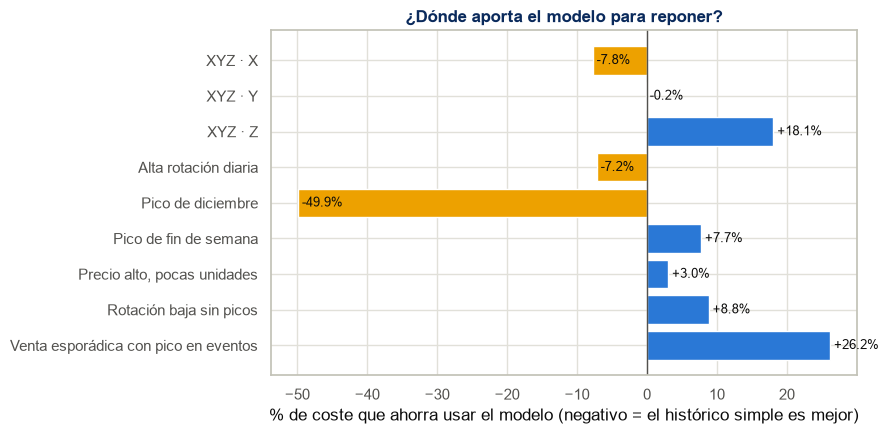

In [12]:
orden_seg = [s_ for s_ in tabla_seg.index if s_.startswith('XYZ')] + \
            [s_ for s_ in tabla_seg.index if not s_.startswith('XYZ')]
valores = tabla_seg.loc[orden_seg, 'ahorro del modelo %']
fig, ax = plt.subplots(figsize=(9, 4.5))
colores = [DSMARKET_BLUE if v > 0 else DSMARKET_GOLD for v in valores]
ax.barh(orden_seg[::-1], valores[::-1], color=colores[::-1])
ax.axvline(0, color='#52514e', linewidth=1)
ax.set_xlabel('% de coste que ahorra usar el modelo (negativo = el histórico simple es mejor)')
ax.set_title('¿Dónde aporta el modelo para reponer?', color=DSMARKET_NAVY, fontweight='bold')
for i, v in enumerate(valores[::-1]):
    ax.text(v, i, f' {v:+.1f}%', va='center', fontsize=9)
plt.tight_layout(); plt.show()

**Hallazgo: el modelo ayuda más justo donde peor predice, y conviene explicar por qué.**

| Segmento | Ahorro de reponer con el modelo |
|---|---|
| XYZ · X (demanda estable) | **−7,8 %** (el histórico simple es mejor) |
| XYZ · Y | −0,2 % (empate) |
| XYZ · Z (demanda errática) | **+18,1 %** |
| Alta rotación diaria | **−7,2 %** |
| Venta esporádica con pico en eventos | **+26,2 %** |
| Pico de diciembre | −49,9 % |

En la Tarea 3 (sección 8), el grupo con menor error de predicción era **Alta rotación diaria** (WAPE semanal del 35 %) y el peor **Venta esporádica con pico en eventos** (68 %). Si la política se eligiera por el error de predicción, se usaría el modelo en el grupo de alta rotación y una regla simple en el de venta esporádica. **La simulación dice lo contrario: el modelo ahorra un 26 % en la venta esporádica y pierde un 7 % en la alta rotación diaria.**

La explicación está en qué mide cada cosa:

- El **RMSSE mide el acierto día a día**. La reposición no usa eso: usa **cuánto se puede vender en nueve días** (los siete del ciclo más los dos de entrega). Son preguntas distintas y no tienen por qué ordenarse igual.
- En una serie **estable y de mucho volumen**, el percentil de las ventas históricas en ventanas de nueve días ya es un estimador excelente: hay muchos datos y el comportamiento no cambia. El modelo, en cambio, suma la incertidumbre de cada día **como si los días fueran independientes**, y eso se queda corto cuando un día alto suele ir seguido de otro alto, que es lo habitual en estas series.
- En una serie **errática**, el percentil de los últimos 180 días es ruidoso y se queda desfasado. El modelo, que tiene en cuenta el nivel reciente y el calendario, sí aporta.

**Pico de diciembre** es la excepción: el modelo sale peor, pero son productos fuera de temporada en esta ventana (marzo-abril) y el importe es pequeño (unos 800 $ de 67.600 $). Como ya señalaba la Tarea 3, este grupo necesita una regla de temporada propia.

**La lección metodológica:** *una métrica de error de predicción no sustituye a la métrica de negocio.* Elegir la política mirando el RMSSE habría llevado a la decisión contraria a la correcta. La forma de decidir es simular la política y medir su coste, que es lo que se ha hecho aquí.

## 7. La política recomendada

La política tiene dos decisiones, y las dos se toman con la simulación:

1. **Cómo se calcula el nivel objetivo de cada serie.** El resultado de la sección 6 sugiere una política **híbrida**: el percentil histórico en las series estables (X), donde es suficiente, y el modelo en las variables y erráticas (Y, Z), donde aporta. Se compara con las dos alternativas puras **al mismo nivel objetivo (90%)**.
2. **A qué nivel de servicio apuntar.** No se fija a mano por celda: sale de la curva servicio-coste de la sección 5, y depende sobre todo de la merma.

In [13]:
def nivel_hibrido_a(sl):
    """Nivel objetivo híbrido para un nivel de servicio dado: percentil histórico en X, modelo en Y/Z."""
    emp = np.percentile(ventanas_hist, sl * 100, axis=1)
    z = norm.ppf(sl)
    return lambda t: np.where(clase_xyz == 'X', emp, nivel_objetivo(t, sig_mod_ext, z))

usa_empirico = (clase_xyz == 'X')
sim_hib = simular(nivel_hibrido_a(0.90))
finales = pd.DataFrame([economia(resultados['Actual (a la predicción media)'], 'Actual (referencia)'),
                        economia(sim_sin, 'Solo percentil empírico (90%)'),
                        economia(sim_con, 'Solo modelo (90%)'),
                        economia(sim_hib, 'Híbrida: empírico en X, modelo en Y/Z (90%)')]
                       ).set_index('política')
finales.round(1)

,nivel de servicio %,unidades perdidas,inventario medio (uds),margen perdido USD,mantenimiento USD,coste total USD,remanente final (uds)
política,,,,,,,
Actual (referencia),86.6,159038.5,197604.3,164543.4,11156.0,175699.4,140932.2
Solo percentil empírico (90%),95.9,47969.2,383913.3,48686.0,21727.8,70413.9,332082.1
Solo modelo (90%),95.9,48945.1,339586.3,47651.5,19943.8,67595.3,279790.2
"Híbrida: empírico en X, modelo en Y/Z (90%)",96.2,45221.1,365396.1,44780.3,21076.0,65856.2,315577.9


In [14]:
# El mismo análisis a lo largo de toda la curva: ¿la híbrida gana a cualquier nivel de servicio?
filas = []
for sl in [0.85, 0.90, 0.95, 0.98]:
    for nombre, fn in [('Solo modelo', lambda t, z=norm.ppf(sl): nivel_objetivo(t, sig_mod_ext, z)),
                       ('Híbrida', nivel_hibrido_a(sl))]:
        e_ = economia(simular(fn), nombre)
        filas.append({'objetivo': f"{sl:.0%}", 'política': nombre, 'servicio %': e_['nivel de servicio %'],
                      'coste total USD': e_['coste total USD'], 'inventario medio (uds)': e_['inventario medio (uds)']})
curva_hib = pd.DataFrame(filas).pivot(index='objetivo', columns='política',
                                      values=['servicio %', 'coste total USD'])
curva_hib.round(1)

servicio %             coste total USD            
política    Híbrida Solo modelo         Híbrida Solo modelo
objetivo                                                   
85%            95.1        94.9         76502.2     77973.0
90%            96.2        95.9         65856.2     67597.0
95%            97.3        97.0         55701.0     57258.9
98%            98.1        97.8         50122.4     50688.6

**La política que proponemos: híbrida según la clase XYZ.**

| Política (objetivo 90 %) | Servicio | Coste total (28 días) |
|---|---|---|
| Actual (referencia) | 86,6 % | 175.699 $ |
| Solo percentil empírico | 95,9 % | 70.414 $ |
| Solo modelo | 95,9 % | 67.595 $ |
| **Híbrida (empírico en X, modelo en Y y Z)** | **96,2 %** | **65.856 $** |

La híbrida **mejora a las dos alternativas puras**: más servicio *y* menos coste que cualquiera de las dos. Es un 2,6 % mejor que la mejor política pura y un **62,5 % mejor que la actual**. Y no depende del objetivo elegido: con objetivos del 85 %, 90 %, 95 % y 98 % la híbrida da siempre más servicio y menos coste que el modelo solo.

En la práctica, la propuesta tiene **dos decisiones separadas**:

| Decisión | Regla | De dónde sale |
|---|---|---|
| **Cómo se calcula el stock objetivo** | Clase X: percentil de las ventas históricas en ventanas de 9 días. Clases Y y Z (incluida CZ): predicción del modelo más su margen de incertidumbre. | Sección 6: el modelo gana en Z, pierde en X y empata en Y. |
| **Qué nivel de servicio se pide** | **SUPERMARKET: 90 %.** **ACCESORIES y HOME_&_GARDEN: 95 %.** | Sección 5.1: con un 10 % de merma el óptimo es el 90 %, con un 5 % es el 95 %. Son valores provisionales hasta medir la merma real. |

Todas las series se revisan **cada semana**. Las de la celda CZ se reponen igual que el resto, con el modelo, pero conviene **revisar periódicamente si deben seguir en el surtido**: son el 28 % del catálogo y aportan el 3,5 % de la facturación.

Dos aclaraciones sobre estos números:

1. **Los ahorros son del periodo simulado, no una promesa.** La simulación usa la demanda real, lo que es correcto para comparar políticas entre sí, pero supone que la demanda no habría cambiado con más producto en el lineal. En la realidad, tener producto disponible probablemente *aumente* las ventas.
2. **La comparación se hizo sobre cuatro semanas de marzo-abril.** Con 400 días de historia el modelo ya aprende Navidad y Thanksgiving (notebook 03, sección 9.2), pero la política de reposición no se ha simulado en temporada alta.

## 8. Cómo se lleva esto a producción: diseño del servicio

*(Sección opcional del enunciado. El diseño está implementado como prototipo en `api/main.py`.)*

El cálculo de la sección 7 no sirve de nada si vive en un notebook. La forma natural de integrarlo con los sistemas de DSMarket es un servicio que responda una sola pregunta: **¿cuánto pido de este producto para esta tienda?**

### Arquitectura propuesta

```
                   ┌──────────────────────────────┐
   ventas diarias  │  1. Ingesta y features       │  batch nocturno
   precios         │     (ventas, precios,        │
   calendario      │      calendario, grupos)     │
                   └──────────────┬───────────────┘
                                  ▼
                   ┌──────────────────────────────┐
                   │  2. Entrenamiento semanal    │  LightGBM media + p90,
                   │     400 días de historia     │  (domingo de madrugada)
                   └──────────────┬───────────────┘
                                  ▼
                   ┌──────────────────────────────┐
                   │  3. Predicción diaria        │  28 días x 30.490 series
                   │     → tabla de predicciones  │
                   └──────────────┬───────────────┘
                                  ▼
   parámetros ───► ┌──────────────────────────────┐ ◄─── inventario actual
   (R, L, servicio)│  4. API de reposición        │      (sistema de tienda)
                   │     calcula S y el pedido    │
                   └──────────────┬───────────────┘
                                  ▼
                        ERP / sistema de compras
```

### Contrato de la API

**`POST /reposicion/sugerencia`** — se pide para una tienda, una fecha de revisión y una lista de productos con su stock; la respuesta devuelve el nivel objetivo y el pedido sugerido de cada uno. El ejemplo siguiente no es inventado: está calculado con la política de la sección 7 para un producto real de la clase AX en la primera revisión de la ventana simulada.

In [15]:
import json
# un producto real AX (alta facturación, demanda estable) de la tienda NYC_1, con la política híbrida
tienda_ej = 'NYC_1'
cand = np.nonzero((meta['store_code'].values == tienda_ej) & (celda == 'AX') & activo)[0]
i = cand[np.argmax(facturacion[cand])]
sl = 0.95
nivel = nivel_hibrido_a(sl)(0)[i]
demanda_esp = media_pred[i, :VENTANA].sum() if clase_xyz[i] != 'X' else np.percentile(ventanas_hist[i], 50)
stock_actual, en_transito = round(0.4 * nivel), 0
peticion = {"tienda": tienda_ej, "fecha_revision": str(calendar['date'].iloc[s].date()),
            "productos": [{"item": meta['item'].iloc[i], "stock_actual": stock_actual, "en_transito": en_transito}],
            "parametros": {"dias_revision": R, "lead_time": L, "nivel_servicio": sl}}
respuesta = {"fecha_revision": peticion["fecha_revision"],
             "cobertura_hasta": str(calendar['date'].iloc[s + VENTANA].date()),
             "sugerencias": [{"item": meta['item'].iloc[i], "grupo_producto": meta['grupo'].iloc[i],
                              "segmento": str(celda[i]),
                              "demanda_esperada": round(float(demanda_esp), 1),
                              "nivel_objetivo": round(float(nivel), 1),
                              "pedido_sugerido": int(max(np.ceil(nivel - stock_actual - en_transito), 0)),
                              "nivel_servicio_aplicado": sl,
                              "metodo": "percentil empírico" if clase_xyz[i] == 'X' else "modelo cuantílico",
                              "motivo": "serie estable (clase X): el histórico de ventanas de 9 días es más fiable que el modelo"
                                        if clase_xyz[i] == 'X' else "serie variable: el modelo estima mejor la incertidumbre"}]}
print("Petición:"); print(json.dumps(peticion, indent=2, ensure_ascii=False))
print("\nRespuesta:"); print(json.dumps(respuesta, indent=2, ensure_ascii=False))

Petición:
{
  "tienda": "NYC_1",
  "fecha_revision": "2016-03-28",
  "productos": [
    {
      "item": "ACCESORIES_1_354",
      "stock_actual": 33,
      "en_transito": 0
    }
  ],
  "parametros": {
    "dias_revision": 7,
    "lead_time": 2,
    "nivel_servicio": 0.95
  }
}

Respuesta:
{
  "fecha_revision": "2016-03-28",
  "cobertura_hasta": "2016-04-06",
  "sugerencias": [
    {
      "item": "ACCESORIES_1_354",
      "grupo_producto": "Precio alto, pocas unidades",
      "segmento": "AX",
      "demanda_esperada": 66.0,
      "nivel_objetivo": 83.0,
      "pedido_sugerido": 50,
      "nivel_servicio_aplicado": 0.95,
      "metodo": "percentil empírico",
      "motivo": "serie estable (clase X): el histórico de ventanas de 9 días es más fiable que el modelo"
    }
  ]
}


Tres decisiones de diseño que conviene justificar:

- **La API no predice, lee predicciones.** El modelo corre en batch y deja las predicciones en tabla; la API solo resuelve la aritmética de la política. Así responde en milisegundos y el pico de carga de las revisiones semanales no depende del modelo. La regla de la sección 7 (niveles de servicio por categoría, percentil empírico en la clase X, modelo en Y y Z, y relleno de la ventana cuando la cobertura se sale del horizonte predicho) está escrita **una sola vez**, en `operacion/politica.py`, y la usan la API, la app, la etapa de reposición y la carga del almacén; una prueba automática comprueba que la API y el almacén dan el mismo nivel objetivo.
- **Los parámetros viajan en la petición**, no están fijos en el código. Permite que Finanzas cambie el nivel de servicio por categoría sin tocar el servicio, y que se pruebe un cambio en unas tiendas antes de extenderlo.
- **Cada sugerencia se explica.** Devolver el segmento y el motivo es lo que hace que un encargado de tienda confíe en el número en vez de ignorarlo — y en la práctica es lo que decide si el proyecto se usa o no.

### Qué hay que vigilar

| Métrica | Para qué | Alerta |
|---|---|---|
| Nivel de servicio real vs objetivo | El sistema cumple lo que promete | Desviación > 3 pp durante 2 semanas |
| Sesgo de la predicción | Detecta el problema de la Tarea 3 | Sesgo > ±3% sostenido |
| Cobertura real del p90 | El intervalo sigue calibrado | Fuera del rango 87-93% |
| Rotación e inventario medio | El coste no se dispara | Inventario > 15% sobre el plan |
| % de sugerencias modificadas a mano | Si el equipo confía en el sistema | > 30% |

## 9. De tres ciudades al resto del país

*(Sección opcional del enunciado.)*

El proyecto piloto cubre 10 tiendas. La pregunta de Michelle es qué pasa al multiplicar por cien.

**Lo que escala sin problema.** El modelo es global: una sola instancia aprende de todas las series. Pasar de 30.490 a 3 millones de series multiplica el volumen de datos, pero no la complejidad del sistema — y el entrenamiento es paralelizable por partición temporal. Con la infraestructura adecuada (Spark o Dask para features, entrenamiento distribuido), el coste crece de forma aproximadamente lineal, no explosiva.

**Lo que NO escala directamente, y es lo importante:**

1. **Una tienda nueva no tiene historia.** Es el problema de arranque en frío, y es donde la Tarea 2 deja el aporte más concreto: en vez de esperar un año de datos, se arranca con el perfil de demanda de la **tienda existente que se espere más parecida** (por tipo de zona y de clientela), siguiendo la comparación de tiendas de la Tarea 2 (sección 5.3). El hallazgo de esa sección es que el perfil de venta **cruza fronteras de ciudad** (Tribeca se parece más a las tiendas de Boston que a las de New York), así que el criterio no debe ser la ciudad.
2. **Los supuestos económicos no son nacionales.** Márgenes, costes logísticos y plazos de entrega cambian por región. Los parámetros de la política tienen que ser configurables por tienda o por región, no constantes.
3. **La validación tiene que ser continua.** Con 10 tiendas se puede revisar a mano; con 1.000 hace falta el seguimiento automático de la sección 8, o los problemas se detectan cuando ya costaron dinero.

**Plan por fases sugerido:**

| Fase | Alcance | Objetivo |
|---|---|---|
| 1 (2 meses) | 2 tiendas piloto, categoría SUPERMARKET | Validar el nivel de servicio real contra el simulado y medir la merma real |
| 2 (3 meses) | Las 10 tiendas, todas las categorías | Ajustar parámetros por categoría; medir el ahorro real contra la línea base |
| 3 (6 meses) | Despliegue nacional progresivo | Cada tienda nueva arranca con el perfil de la tienda existente más parecida, no con la media de su ciudad |

La fase 1 no es opcional: **la merma real es el parámetro que decide la política entera** (sección 5.1) y hoy no lo tenemos medido.

## 10. Estado de la Tarea 4 y qué necesitamos de DSMarket

**Lo que queda propuesto y cuantificado:**

| Pedido del enunciado | Resultado |
|---|---|
| Cómo aplicar los modelos a la reposición semanal o diaria | Política de revisión periódica (R=7, L=2) con stock objetivo híbrido, simulada sobre 30.490 series y 4 semanas reales |
| Stock mínimo | Stock de seguridad por serie: el método depende de la clase XYZ y el nivel de servicio de la categoría (merma) |
| Minimizar el remanente | Curva servicio-coste completa; el nivel óptimo va del 80 % al 99 % según la merma (sección 5.1) |
| Diseño de API *(opcional)* | Sección 8: arquitectura, contrato y métricas de seguimiento |
| Plan de escalabilidad *(opcional)* | Sección 9: qué escala solo, qué no, y plan en tres fases |

**El resultado central:** pasar de "pedir lo que dice la previsión" a una política con stock de seguridad sube el nivel de servicio del 86,6 % al 96,2 % y **reduce el coste total un 62,5 %** en el periodo simulado. La mayor parte del ahorro no viene del modelo sino de una idea de gestión, tener algo más de lo que dice la previsión, y el modelo aporta el ajuste fino: *cuánto* más, y en qué productos.

**Los tres datos que necesitamos de DSMarket para cerrar la propuesta:**

1. **La merma por categoría.** Decide el nivel de servicio objetivo, y es el único supuesto que puede mover la recomendación de un extremo a otro (del 80 % al 99 %).
2. **El margen bruto real por categoría.** Menos crítico, porque mueve poco el óptimo, pero necesario para traducir el ahorro a dinero real.
3. **El plazo de entrega real por tienda y proveedor.** Se han usado 2 días para todo; si varía, el stock de seguridad tiene que variar con él.

**Lo que queda pendiente:**

- La política **no se ha simulado en temporada alta**. Antes de aplicarla en noviembre y diciembre conviene repetir esta simulación sobre esos meses, con el modelo de 400 días.
- La simulación **no tiene en cuenta el espacio en el lineal**, que en la práctica es un límite duro. Con objetivos del 90-99 % el inventario medio sube entre un 85 % y un 135 %, y puede que no quepa en la tienda.
- **No se modela el efecto de la disponibilidad sobre la demanda.** Es una simplificación habitual, pero hace que los ahorros estimados sean probablemente conservadores.